In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("loan_approval_data (1).csv")

In [3]:
df.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,NaN,Car,Semiurban,Graduate,NaN,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,NaN,Urban,NaN,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,NaN,Graduate,Male,Private,Yes


In [4]:
print(df.shape)
df.isnull().sum()

(1000, 20)


Applicant_ID          50
Applicant_Income      50
Coapplicant_Income    50
Employment_Status     50
Age                   50
Marital_Status        50
Dependents            50
Credit_Score          50
Existing_Loans        50
DTI_Ratio             50
Savings               50
Collateral_Value      50
Loan_Amount           50
Loan_Term             50
Loan_Purpose          50
Property_Area         50
Education_Level       50
Gender                50
Employer_Category     50
Loan_Approved         50
dtype: int64

In [5]:
df.dtypes

Applicant_ID          float64
Applicant_Income      float64
Coapplicant_Income    float64
Employment_Status         str
Age                   float64
Marital_Status            str
Dependents            float64
Credit_Score          float64
Existing_Loans        float64
DTI_Ratio             float64
Savings               float64
Collateral_Value      float64
Loan_Amount           float64
Loan_Term             float64
Loan_Purpose              str
Property_Area             str
Education_Level           str
Gender                    str
Employer_Category         str
Loan_Approved             str
dtype: object

In [6]:
from sklearn.impute import SimpleImputer

In [7]:
mean_imp = SimpleImputer(strategy = "mean")
median_imp = SimpleImputer(strategy = "median")
mode_imp = SimpleImputer(strategy = "most_frequent")


In [8]:
num_cols = ["Applicant_Income" , "Coapplicant_Income" , "Dependents" , "Credit_Score" , "Existing_Loans" , "DTI_Ratio" , "Savings" , "Collateral_Value" , "Loan_Amount" , "Loan_Term"]

In [9]:
catg_cols = ["Employment_Status" , "Marital_Status" , "Loan_Purpose" , "Property_Area" , "Education_Level" , "Gender" , "Employer_Category" , "Loan_Approved" ]

In [10]:
df["Age"].median()

40.0

In [11]:
df[num_cols].dtypes

Applicant_Income      float64
Coapplicant_Income    float64
Dependents            float64
Credit_Score          float64
Existing_Loans        float64
DTI_Ratio             float64
Savings               float64
Collateral_Value      float64
Loan_Amount           float64
Loan_Term             float64
dtype: object

In [12]:
df[num_cols] = mean_imp.fit_transform(df[num_cols])

In [13]:
df[catg_cols] = mode_imp.fit_transform(df[catg_cols])

In [14]:
df["Age"] = median_imp.fit_transform(df[["Age"]])

In [15]:
print(df.isnull().sum())
# print(df.isnull().sum().sum())

Applicant_ID          50
Applicant_Income       0
Coapplicant_Income     0
Employment_Status      0
Age                    0
Marital_Status         0
Dependents             0
Credit_Score           0
Existing_Loans         0
DTI_Ratio              0
Savings                0
Collateral_Value       0
Loan_Amount            0
Loan_Term              0
Loan_Purpose           0
Property_Area          0
Education_Level        0
Gender                 0
Employer_Category      0
Loan_Approved          0
dtype: int64


### EDA

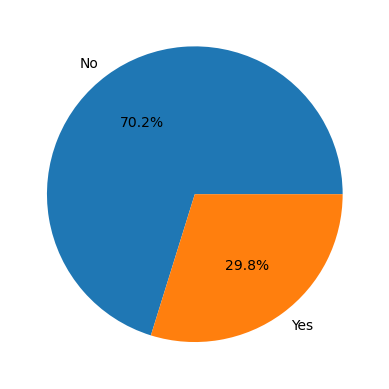

In [16]:
## Visualization

# checking ratio of o/p

plt.pie(df["Loan_Approved"].value_counts() , labels = ["No" , "Yes"] , autopct = "%1.1f%%")
plt.show()

In [17]:
df["Gender"].value_counts()

Gender
Male      621
Female    379
Name: count, dtype: int64

<Axes: xlabel='Gender', ylabel='count'>

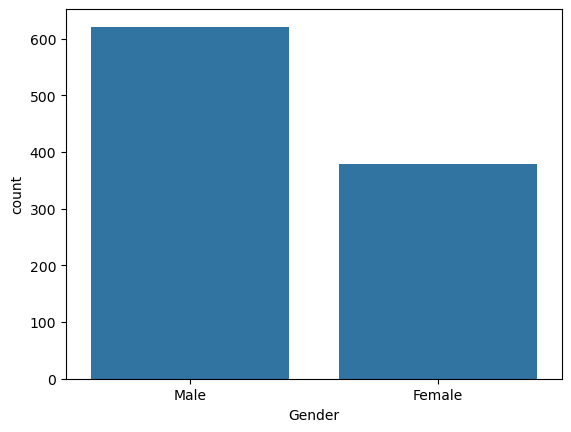

In [18]:
sns.barplot(df["Gender"].value_counts())

<Axes: xlabel='Marital_Status', ylabel='count'>

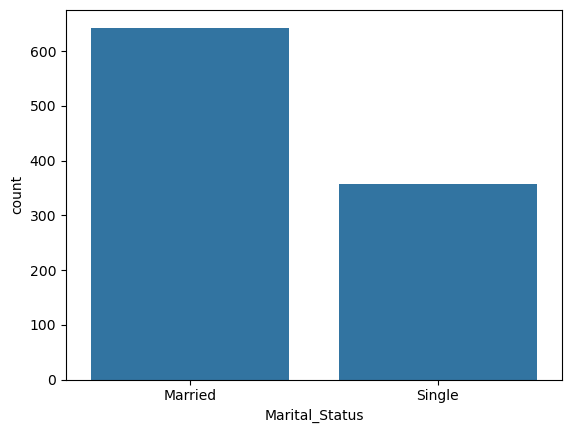

In [19]:
sns.barplot(df["Marital_Status"].value_counts())

<Axes: xlabel='Employment_Status', ylabel='count'>

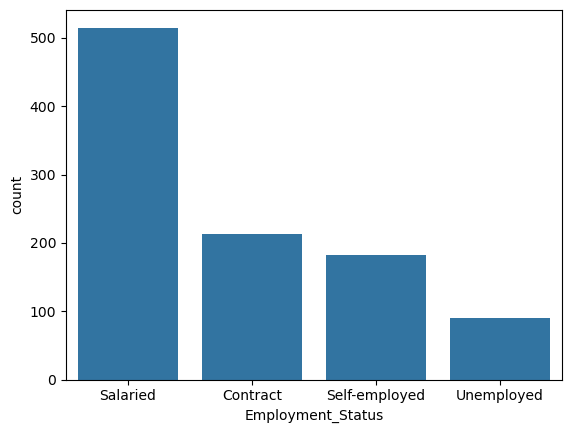

In [20]:
sns.barplot(df["Employment_Status"].value_counts())

<Axes: xlabel='Education_Level', ylabel='count'>

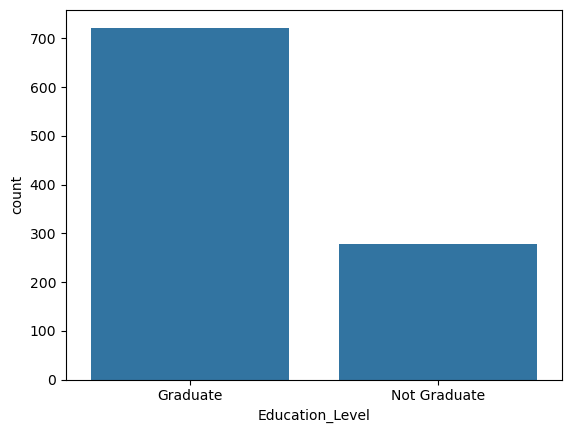

In [21]:
sns.barplot(df["Education_Level"].value_counts())

<Axes: xlabel='DTI_Ratio', ylabel='Count'>

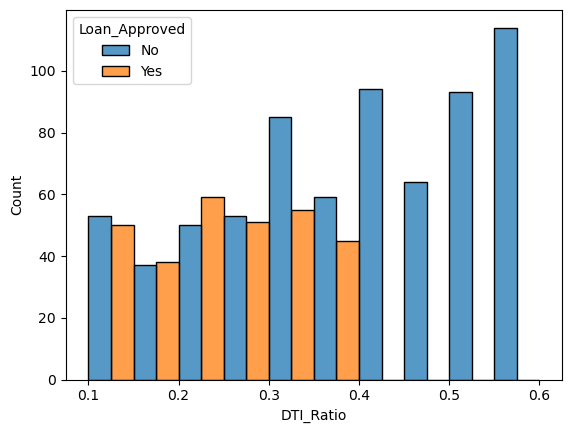

In [22]:
# Histogram

sns.histplot(
    data = df ,
    x = "DTI_Ratio" ,
    bins = 10 ,
    hue = "Loan_Approved" ,
    multiple = "dodge"
)

<Axes: xlabel='DTI_Ratio', ylabel='Count'>

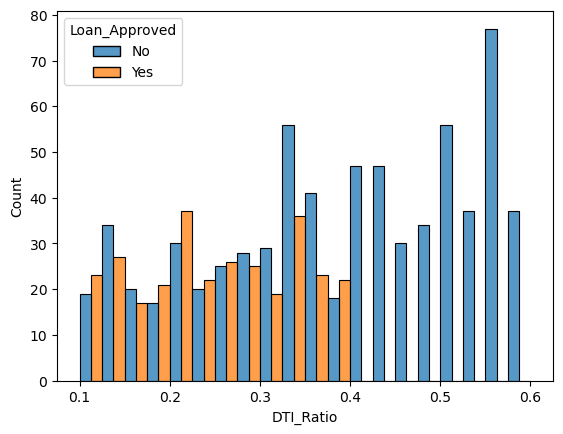

In [23]:
sns.histplot(
    data = df ,
    x = "DTI_Ratio" ,
    bins = 20 ,
    hue = "Loan_Approved" ,
    multiple = "dodge"
)

<Axes: xlabel='Applicant_Income', ylabel='Count'>

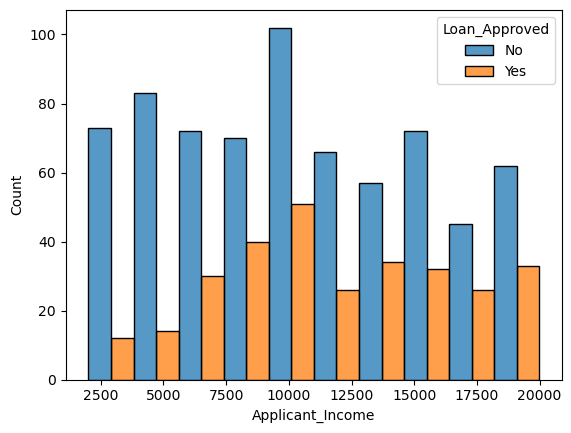

In [24]:
sns.histplot(
    data = df ,
    x = "Applicant_Income" ,
    bins = 10 ,
    hue = "Loan_Approved" ,
    multiple = "dodge"
)

<Axes: xlabel='Loan_Amount', ylabel='Count'>

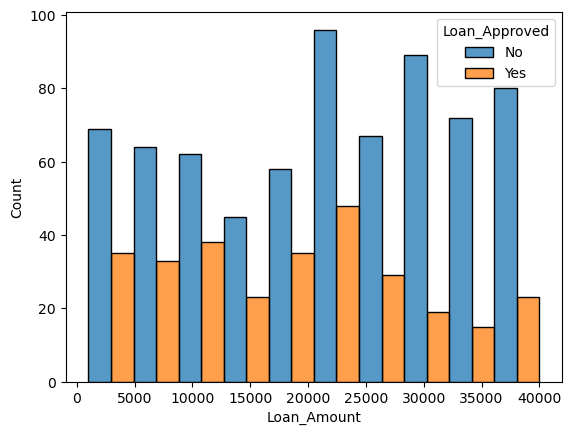

In [25]:
sns.histplot(
    data = df ,
    x = "Loan_Amount" ,
    bins = 10 ,
    hue = "Loan_Approved" ,
    multiple = "dodge"
)

<Axes: xlabel='Savings', ylabel='Count'>

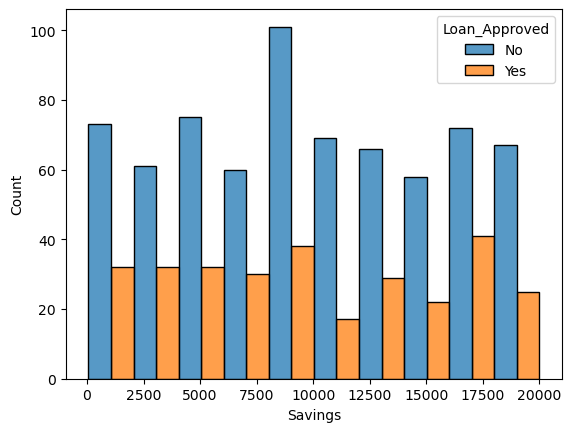

In [26]:
sns.histplot(
    data = df ,
    x = "Savings" ,
    bins = 10 ,
    hue = "Loan_Approved" ,
    multiple = "dodge"
)

<Axes: xlabel='Credit_Score', ylabel='Count'>

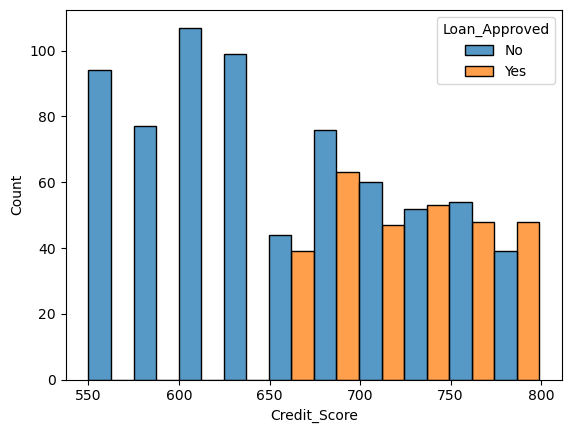

In [27]:
sns.histplot(
    data = df ,
    x = "Credit_Score" ,
    bins = 10 ,
    hue = "Loan_Approved" ,
    multiple = "dodge"
)

<Axes: xlabel='Loan_Approved', ylabel='DTI_Ratio'>

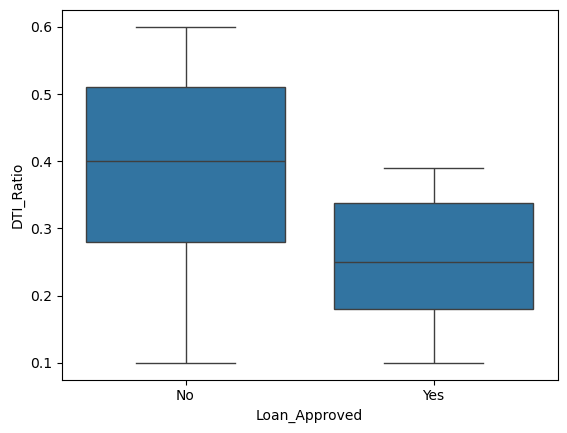

In [28]:
# Outlier detection

sns.boxplot(
    data = df ,
    x = "Loan_Approved" ,
    y = "DTI_Ratio"
)

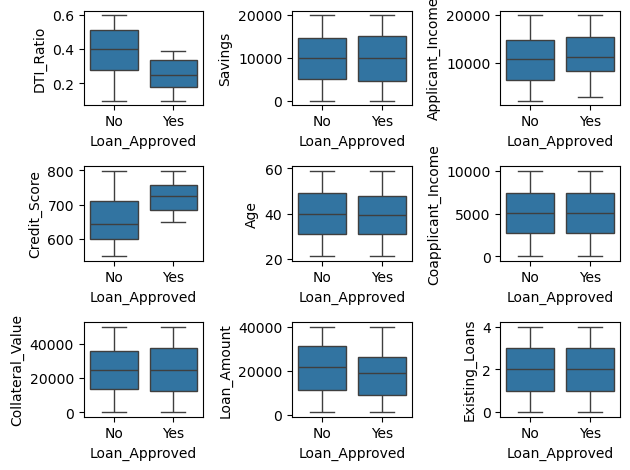

In [29]:
fig , axes = plt.subplots(3,3)
sns.boxplot(
    ax = axes[0,0] ,
    data = df ,
    x = "Loan_Approved" ,
    y = "DTI_Ratio"
)
sns.boxplot(
    ax = axes[0,1] ,
    data = df ,
    x = "Loan_Approved" ,
    y = "Savings"
)
sns.boxplot(
    ax = axes[0,2] ,
    data = df ,
    x = "Loan_Approved" ,
    y = "Applicant_Income"
)
sns.boxplot(
    ax = axes[1,0] ,
    data = df ,
    x = "Loan_Approved" ,
    y = "Credit_Score"
)
sns.boxplot(
    ax = axes[1,1] ,
    data = df ,
    x = "Loan_Approved" ,
    y = "Age"
)
sns.boxplot(
    ax = axes[1,2] ,
    data = df ,
    x = "Loan_Approved" ,
    y = "Coapplicant_Income"
)
sns.boxplot(
    ax = axes[2,0] ,
    data = df ,
    x = "Loan_Approved" ,
    y = "Collateral_Value"
)
sns.boxplot(
    ax = axes[2,1] ,
    data = df ,
    x = "Loan_Approved" ,
    y = "Loan_Amount"
)
sns.boxplot(
    ax = axes[2,2] ,
    data = df ,
    x = "Loan_Approved" ,
    y = "Existing_Loans"
)
plt.tight_layout()


In [30]:
df.dtypes

Applicant_ID          float64
Applicant_Income      float64
Coapplicant_Income    float64
Employment_Status         str
Age                   float64
Marital_Status            str
Dependents            float64
Credit_Score          float64
Existing_Loans        float64
DTI_Ratio             float64
Savings               float64
Collateral_Value      float64
Loan_Amount           float64
Loan_Term             float64
Loan_Purpose              str
Property_Area             str
Education_Level           str
Gender                    str
Employer_Category         str
Loan_Approved             str
dtype: object

In [31]:
from sklearn.preprocessing import LabelEncoder , OneHotEncoder

In [32]:
lb = LabelEncoder()
lb

LabelEncoder()

In [33]:
lb_cols = ["Education_Level" , "Loan_Approved"]

In [34]:
df["Education_Level"] = lb.fit_transform(df["Education_Level"])
df["Loan_Approved"] = lb.fit_transform(df["Loan_Approved"])
df[lb_cols].sample()


# passing individual cols in labelEncoder

,Education_Level,Loan_Approved
894,0,0


In [35]:
hot_cols = ["Loan_Purpose" ,  "Marital_Status" , "Employment_Status" , "Property_Area" , "Gender" , "Employer_Category"]
ohe = OneHotEncoder(drop = "first" , sparse_output = False , handle_unknown = "ignore")
ohe

,categories,'auto'
,drop,'first'
,sparse_output,False
,dtype,<class 'numpy.float64'>
,handle_unknown,'ignore'
,min_frequency,None
,max_categories,None
,feature_name_combiner,'concat'


In [36]:
encoded_hots = ohe.fit_transform(df[hot_cols])
encoded_hots

array([[0., 0., 0., ..., 0., 1., 0.],
       [1., 0., 0., ..., 0., 1., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 1., ..., 1., 0., 0.],
       [0., 0., 0., ..., 0., 1., 0.],
       [0., 0., 0., ..., 0., 1., 0.]], shape=(1000, 15))

In [37]:
encoded_hots

array([[0., 0., 0., ..., 0., 1., 0.],
       [1., 0., 0., ..., 0., 1., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 1., ..., 1., 0., 0.],
       [0., 0., 0., ..., 0., 1., 0.],
       [0., 0., 0., ..., 0., 1., 0.]], shape=(1000, 15))

In [38]:
encoded_df = pd.DataFrame(encoded_hots , columns = ohe.get_feature_names_out(hot_cols) , index = df.index)
encoded_df

,Loan_Purpose_Car,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Marital_Status_Single,Employment_Status_Salaried,Employment_Status_Self-employed,Employment_Status_Unemployed,Property_Area_Semiurban,Property_Area_Urban,Gender_Male,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed
0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
2,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0
996,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
997,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
998,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0


In [39]:
df = pd.concat([df.drop(columns = hot_cols) , encoded_df] , axis = 1)

In [40]:
df.describe()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,...,Employment_Status_Salaried,Employment_Status_Self-employed,Employment_Status_Unemployed,Property_Area_Semiurban,Property_Area_Urban,Gender_Male,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed
count,950.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,...,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,501.220000,10852.571579,5082.455789,39.973000,1.474737,676.033684,1.950526,0.347263,9940.452632,24802.792632,...,0.515000,0.182000,0.090000,0.189000,0.517000,0.621000,0.202000,0.144000,0.422000,0.097000
std,289.608451,4933.339492,2868.563488,10.857447,1.077058,69.537662,1.370603,0.140683,5712.189236,13982.086562,...,0.500025,0.386038,0.286325,0.391705,0.499961,0.485381,0.401693,0.351265,0.494126,0.296106
min,1.000000,2009.000000,1.000000,21.000000,0.000000,550.000000,0.000000,0.100000,65.000000,36.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,250.250000,6857.000000,2701.250000,31.000000,1.000000,618.000000,1.000000,0.230000,4964.000000,13166.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,499.500000,10852.571579,5082.455789,40.000000,1.237368,676.033684,2.000000,0.347263,9940.452632,24802.792632,...,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
75%,752.750000,14973.250000,7452.750000,49.000000,2.000000,735.000000,3.000000,0.470000,14784.750000,36396.000000,...,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
max,1000.000000,19988.000000,9996.000000,59.000000,3.000000,799.000000,4.000000,0.600000,19996.000000,49954.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [41]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 29 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Applicant_ID                     950 non-null    float64
 1   Applicant_Income                 1000 non-null   float64
 2   Coapplicant_Income               1000 non-null   float64
 3   Age                              1000 non-null   float64
 4   Dependents                       1000 non-null   float64
 5   Credit_Score                     1000 non-null   float64
 6   Existing_Loans                   1000 non-null   float64
 7   DTI_Ratio                        1000 non-null   float64
 8   Savings                          1000 non-null   float64
 9   Collateral_Value                 1000 non-null   float64
 10  Loan_Amount                      1000 non-null   float64
 11  Loan_Term                        1000 non-null   float64
 12  Education_Level                 

In [42]:
df.isnull().sum()

Applicant_ID                       50
Applicant_Income                    0
Coapplicant_Income                  0
Age                                 0
Dependents                          0
Credit_Score                        0
Existing_Loans                      0
DTI_Ratio                           0
Savings                             0
Collateral_Value                    0
Loan_Amount                         0
Loan_Term                           0
Education_Level                     0
Loan_Approved                       0
Loan_Purpose_Car                    0
Loan_Purpose_Education              0
Loan_Purpose_Home                   0
Loan_Purpose_Personal               0
Marital_Status_Single               0
Employment_Status_Salaried          0
Employment_Status_Self-employed     0
Employment_Status_Unemployed        0
Property_Area_Semiurban             0
Property_Area_Urban                 0
Gender_Male                         0
Employer_Category_Government        0
Employer_Cat

In [43]:
df.dtypes

Applicant_ID                       float64
Applicant_Income                   float64
Coapplicant_Income                 float64
Age                                float64
Dependents                         float64
Credit_Score                       float64
Existing_Loans                     float64
DTI_Ratio                          float64
Savings                            float64
Collateral_Value                   float64
Loan_Amount                        float64
Loan_Term                          float64
Education_Level                      int64
Loan_Approved                        int64
Loan_Purpose_Car                   float64
Loan_Purpose_Education             float64
Loan_Purpose_Home                  float64
Loan_Purpose_Personal              float64
Marital_Status_Single              float64
Employment_Status_Salaried         float64
Employment_Status_Self-employed    float64
Employment_Status_Unemployed       float64
Property_Area_Semiurban            float64
Property_Ar

### Checking Correalation

In [44]:
corr_matrix = df.corr()
corr_matrix

,Applicant_ID,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,...,Employment_Status_Salaried,Employment_Status_Self-employed,Employment_Status_Unemployed,Property_Area_Semiurban,Property_Area_Urban,Gender_Male,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed
Applicant_ID,1.000000,0.021578,0.041910,0.014919,0.012807,-0.029191,0.025670,0.000179,0.023213,0.032629,...,-0.052865,0.060493,0.003135,0.013182,-0.030969,0.037066,0.006070,-0.075704,0.023410,0.039444
Applicant_Income,0.021578,1.000000,0.007545,-0.024018,-0.026658,-0.009818,-0.010457,-0.009107,-0.028358,0.018789,...,-0.000863,0.005609,0.001419,0.004845,-0.036260,-0.020871,-0.025011,0.102589,-0.044639,-0.011995
Coapplicant_Income,0.041910,0.007545,1.000000,0.014316,-0.026733,0.058423,0.012418,0.058078,-0.015047,0.009457,...,-0.013517,-0.010462,0.023114,-0.010058,0.030045,-0.010148,-0.001146,0.037640,0.004312,-0.047929
Age,0.014919,-0.024018,0.014316,1.000000,-0.018771,-0.004217,0.023331,0.007933,-0.000986,0.037401,...,-0.000202,-0.011723,-0.009843,0.003084,-0.025640,0.048391,-0.065996,0.021230,-0.012987,0.072428
Dependents,0.012807,-0.026658,-0.026733,-0.018771,1.000000,-0.007687,-0.026338,0.011498,-0.004981,0.023004,...,-0.034611,0.079136,0.000396,-0.032278,0.024082,0.013706,-0.009250,-0.018757,0.030197,-0.054147
Credit_Score,-0.029191,-0.009818,0.058423,-0.004217,-0.007687,1.000000,-0.007130,0.002338,-0.065353,0.007865,...,-0.016627,-0.035896,-0.008344,-0.006946,0.004445,-0.039739,-0.007076,0.066736,-0.000049,-0.046087
Existing_Loans,0.025670,-0.010457,0.012418,0.023331,-0.026338,-0.007130,1.000000,0.047008,0.034435,-0.049916,...,-0.004462,0.042772,-0.012356,-0.053971,0.035629,-0.038762,-0.009642,0.030520,-0.019306,0.045391
DTI_Ratio,0.000179,-0.009107,0.058078,0.007933,0.011498,0.002338,0.047008,1.000000,0.004663,-0.009622,...,0.031658,-0.043904,0.022318,0.044898,-0.006156,0.009624,-0.007214,0.002090,-0.003506,0.026018
Savings,0.023213,-0.028358,-0.015047,-0.000986,-0.004981,-0.065353,0.034435,0.004663,1.000000,0.015481,...,0.022435,0.000668,0.006304,0.005438,0.016833,-0.006667,-0.011683,0.004381,-0.030208,0.027178
Collateral_Value,0.032629,0.018789,0.009457,0.037401,0.023004,0.007865,-0.049916,-0.009622,0.015481,1.000000,...,-0.019882,0.000119,-0.041632,0.020061,0.007975,0.000897,0.035760,-0.013464,-0.014480,-0.009655


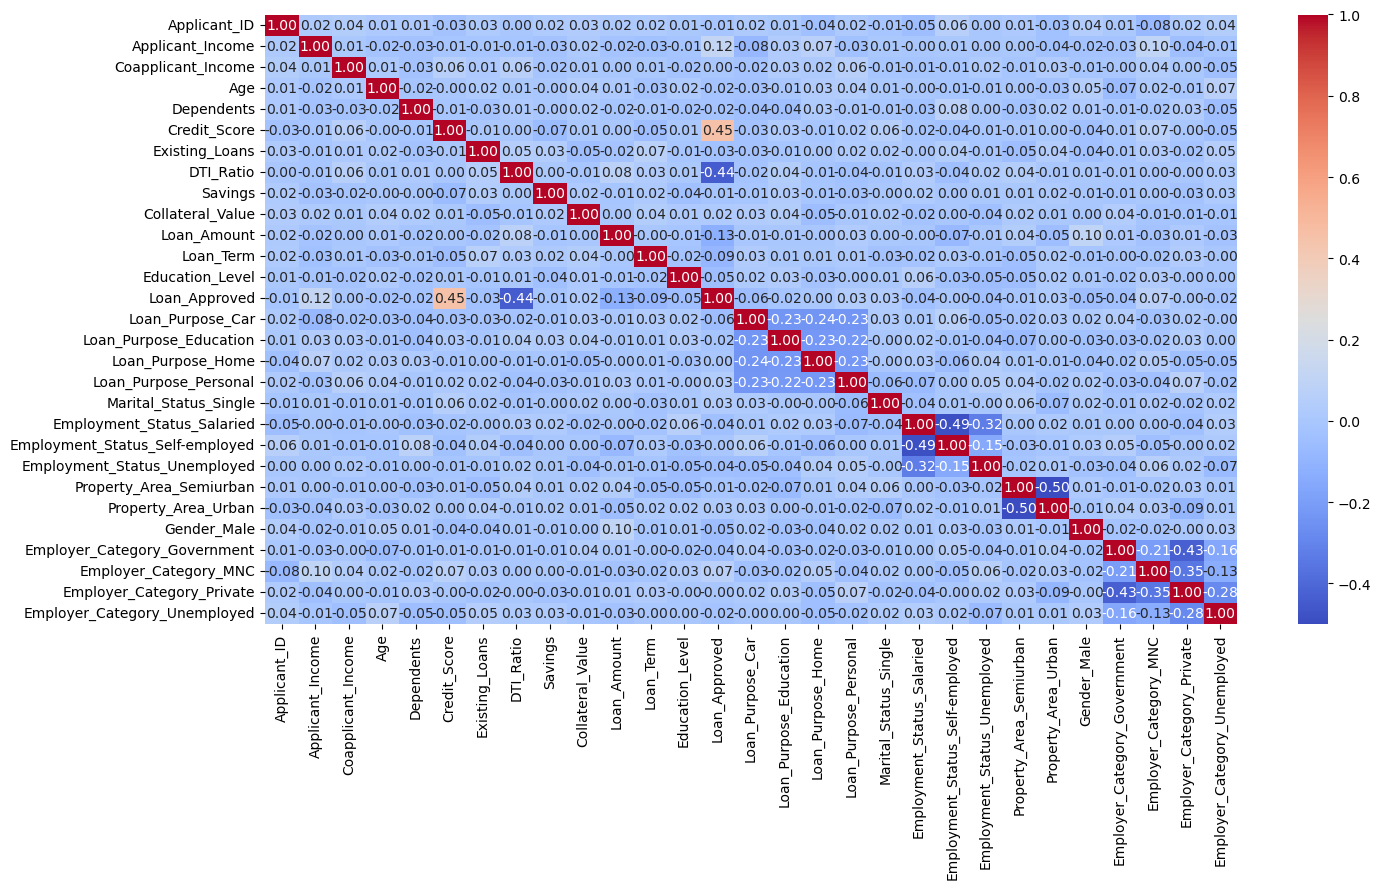

In [45]:
plt.figure(figsize = (15 , 9))
sns.heatmap(
    corr_matrix ,
    annot = True ,
    fmt = ".2f" ,
    cmap = "coolwarm"
)
plt.tight_layout()

In [46]:
### Train Test Split

X = df.drop(columns = ["Applicant_ID" , "Loan_Approved"])
y = df["Loan_Approved"]

In [47]:
X_train , X_test , y_train , y_test = train_test_split(X , y , test_size = 0.2 , random_state = 42)

In [48]:
X

,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,...,Employment_Status_Salaried,Employment_Status_Self-employed,Employment_Status_Unemployed,Property_Area_Semiurban,Property_Area_Urban,Gender_Male,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed
0,17795.000000,1387.0,51.0,0.0,637.0,4.0,0.53,19403.000000,45638.0,16619.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,2860.000000,2679.0,46.0,3.0,621.0,2.0,0.30,2580.000000,49272.0,38687.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
2,7390.000000,2106.0,25.0,2.0,674.0,4.0,0.20,13844.000000,6908.0,27943.0,...,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
3,13964.000000,8173.0,40.0,2.0,579.0,3.0,0.31,9553.000000,10844.0,27819.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,13284.000000,4223.0,31.0,2.0,721.0,1.0,0.29,9386.000000,37629.0,12741.0,...,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,10852.571579,9092.0,58.0,0.0,557.0,0.0,0.59,5370.000000,43563.0,8311.0,...,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0
996,3279.000000,6356.0,58.0,1.0,646.0,3.0,0.19,9940.452632,18361.0,22563.0,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
997,15192.000000,8433.0,48.0,1.0,666.0,1.0,0.40,8581.000000,41335.0,16203.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
998,9083.000000,7380.0,50.0,1.0,748.0,3.0,0.31,13491.000000,8933.0,10290.0,...,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0


In [49]:
X_test

,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,...,Employment_Status_Salaried,Employment_Status_Self-employed,Employment_Status_Unemployed,Property_Area_Semiurban,Property_Area_Urban,Gender_Male,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed
521,13023.0,6675.0,53.0,3.0,628.0,3.0,0.347263,10051.000000,26309.000000,22947.000000,...,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
737,15917.0,6787.0,42.0,0.0,588.0,4.0,0.410000,922.000000,13476.000000,20522.825263,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
740,7560.0,3530.0,52.0,3.0,606.0,0.0,0.580000,9940.452632,21795.000000,5876.000000,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
660,19022.0,574.0,59.0,0.0,725.0,4.0,0.410000,1463.000000,44498.000000,8433.000000,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
411,4967.0,5797.0,40.0,3.0,697.0,4.0,0.580000,1095.000000,3017.000000,33926.000000,...,1.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
408,2728.0,1875.0,30.0,2.0,787.0,4.0,0.340000,12889.000000,17502.000000,34649.000000,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
332,10308.0,9109.0,28.0,2.0,556.0,4.0,0.340000,8606.000000,24802.792632,7336.000000,...,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
208,7539.0,4805.0,54.0,3.0,796.0,1.0,0.160000,12123.000000,43856.000000,18675.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
613,9043.0,2289.0,34.0,0.0,651.0,3.0,0.350000,15823.000000,49262.000000,29080.000000,...,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0


In [50]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)

In [51]:
X_test = scaler.transform(X_test)

### Model training and Evaluation

In [52]:
# 3.  Naive Bayes

from sklearn.naive_bayes import GaussianNB

In [53]:
model = GaussianNB()
model.fit(X_train , y_train)
y_pred = model.predict(X_test)

In [54]:
from sklearn.metrics import accuracy_score , precision_score , recall_score , f1_score , confusion_matrix , classification_report
print(f"Model Accuracy = {accuracy_score(y_test , y_pred)}")
print(f"Model Precision = {precision_score(y_test , y_pred)}")
print(f"Model Reacall = {recall_score(y_test , y_pred)}")
print(f"Model F1-score = {f1_score(y_test , y_pred)}")
print(f"Model Confusion Matrix = {confusion_matrix(y_test , y_pred)}")
print("Model classifiaction Report = ")
print(f"{classification_report(y_test , y_pred)}")

Model Accuracy = 0.865
Model Precision = 0.8035714285714286
Model Reacall = 0.7377049180327869
Model F1-score = 0.7692307692307693
Model Confusion Matrix = [[128  11]
 [ 16  45]]
Model classifiaction Report = 
              precision    recall  f1-score   support

           0       0.89      0.92      0.90       139
           1       0.80      0.74      0.77        61

    accuracy                           0.86       200
   macro avg       0.85      0.83      0.84       200
weighted avg       0.86      0.86      0.86       200



In [60]:
import joblib

In [61]:
joblib.dump(model , "loan_modell.pkl")

['loan_modell.pkl']

In [62]:
import joblib

preprocessing = {
    "mean_imputer": mean_imp,
    "median_imputer": median_imp,
    "mode_imputer": mode_imp,
    "onehot_encoder": ohe,
    "scaler": scaler,
    "feature_columns": X.columns.tolist()
}

joblib.dump(preprocessing, "preprocessing.pkl")

['preprocessing.pkl']

In [63]:
raw_df = pd.read_csv("loan_approval_data (1).csv")

edu_encoder = LabelEncoder()

edu_values = raw_df["Education_Level"].fillna(
    mode_imp.statistics_[catg_cols.index("Education_Level")]
)

edu_encoder.fit(edu_values)

LabelEncoder()

In [64]:
preprocessing["education_encoder"] = edu_encoder
preprocessing["loan_classes"] = lb.classes_

joblib.dump(preprocessing, "preprocessing.pkl")

['preprocessing.pkl']

In [65]:
print("Education Levels:")
print(edu_encoder.classes_)

print("\nLoan Purposes:")
print(ohe.categories_[0])

print("\nMarital Status:")
print(ohe.categories_[1])

print("\nEmployment Status:")
print(ohe.categories_[2])

print("\nProperty Areas:")
print(ohe.categories_[3])

print("\nGender:")
print(ohe.categories_[4])

print("\nEmployer Categories:")
print(ohe.categories_[5])

print("\nFinal Model Features:")
print(X.columns.tolist())

Education Levels:
['Graduate' 'Not Graduate']

Loan Purposes:
['Business' 'Car' 'Education' 'Home' 'Personal']

Marital Status:
['Married' 'Single']

Employment Status:
['Contract' 'Salaried' 'Self-employed' 'Unemployed']

Property Areas:
['Rural' 'Semiurban' 'Urban']

Gender:
['Female' 'Male']

Employer Categories:
['Business' 'Government' 'MNC' 'Private' 'Unemployed']

Final Model Features:
['Applicant_Income', 'Coapplicant_Income', 'Age', 'Dependents', 'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings', 'Collateral_Value', 'Loan_Amount', 'Loan_Term', 'Education_Level', 'Loan_Purpose_Car', 'Loan_Purpose_Education', 'Loan_Purpose_Home', 'Loan_Purpose_Personal', 'Marital_Status_Single', 'Employment_Status_Salaried', 'Employment_Status_Self-employed', 'Employment_Status_Unemployed', 'Property_Area_Semiurban', 'Property_Area_Urban', 'Gender_Male', 'Employer_Category_Government', 'Employer_Category_MNC', 'Employer_Category_Private', 'Employer_Category_Unemployed']


In [66]:
print("Education:", edu_encoder.classes_)
print("Loan Purpose:", ohe.categories_[0])
print("Marital Status:", ohe.categories_[1])
print("Employment:", ohe.categories_[2])
print("Property Area:", ohe.categories_[3])
print("Gender:", ohe.categories_[4])
print("Employer Category:", ohe.categories_[5])

print("Features:", X.columns.tolist())

Education: ['Graduate' 'Not Graduate']
Loan Purpose: ['Business' 'Car' 'Education' 'Home' 'Personal']
Marital Status: ['Married' 'Single']
Employment: ['Contract' 'Salaried' 'Self-employed' 'Unemployed']
Property Area: ['Rural' 'Semiurban' 'Urban']
Gender: ['Female' 'Male']
Employer Category: ['Business' 'Government' 'MNC' 'Private' 'Unemployed']
Features: ['Applicant_Income', 'Coapplicant_Income', 'Age', 'Dependents', 'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings', 'Collateral_Value', 'Loan_Amount', 'Loan_Term', 'Education_Level', 'Loan_Purpose_Car', 'Loan_Purpose_Education', 'Loan_Purpose_Home', 'Loan_Purpose_Personal', 'Marital_Status_Single', 'Employment_Status_Salaried', 'Employment_Status_Self-employed', 'Employment_Status_Unemployed', 'Property_Area_Semiurban', 'Property_Area_Urban', 'Gender_Male', 'Employer_Category_Government', 'Employer_Category_MNC', 'Employer_Category_Private', 'Employer_Category_Unemployed']


In [67]:
print(lb.classes_)

['No' 'Yes']
